In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict, Annotated, Literal
from pydantic import BaseModel, Field
from dotenv import load_dotenv
import operator
import os


load_dotenv()
api_key = os.getenv("GEMINI_API_KEY")


In [2]:
llm = ChatGoogleGenerativeAI(
    model = "gemini-3.5-flash-lite",
    api_key = api_key
)

In [1]:
from google import genai
import os

client = genai.Client(api_key=os.getenv("GOOGLE_API_KEY"))

for model in client.models.list():
    print(model.name)

models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-pro-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-pro-preview
models/gemini-3.1-pro-preview-customtools
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3-pro-image-preview
models/gemini-3-pro-image
models/nano-banana-pro-preview
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-nano-banana-2.1
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.5-transcribe
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-4-argon
models/lyria-3-clip-preview
models/lyria-3-pro-preview
models/l

In [4]:
class SentimentStructure(BaseModel):
    sentiment : Annotated[Literal["positive", "neutral", "negative"], Field(description="The emotional Sentiment of the review")]

In [5]:
sentiment_structure_llm = llm.with_structured_output(SentimentStructure)

In [6]:
class DiagnosisStructure(BaseModel):
    issue_type : Annotated[Literal["product_quality", "delivery_issue", "customer_service"], Field(description="What is the type of issue in customer Review") ]
    urgency: Annotated[Literal["low", "medium", "high"],Field(description="How urgently the issue needs attention")]

In [7]:
diagnos_structure_llm = llm.with_structured_output(DiagnosisStructure)

In [8]:
class FeedbackState(TypedDict):
    feedback : str
    sentiment : Literal["positive", "negative", "neutral"]
    issue_type : Literal["product_quality", "delivery_issue", "customer_service"]
    urgency: Literal["low", "medium", "high"]

    positive_response : str
    negative_response : str

In [9]:
def find_sentiment(state:FeedbackState):
    feedback = state['feedback']
    ques = f"What it the sentiment of this feedback '{feedback}'"
    ans = sentiment_structure_llm.invoke(ques)

    return {'sentiment' : ans.sentiment}

In [10]:
def sentimet_router(state : FeedbackState) -> Literal["run_diagnosis", "positive_feedback"]:
    sentiment = state['sentiment']

    if sentiment == "negative":
        return "run_diagnosis"
    else:
        return "positive_feedback"

In [11]:
def run_diagnosis(state: FeedbackState):
    feeback = state['feedback']
    sentiment = state['sentiment']

    ques = f"What is the issue Type and urgency this '{feeback}' have with '{sentiment}' sentiment"
    ans = diagnos_structure_llm.invoke(ques)

    return {'issue_type' : ans.issue_type, 'urgency' : ans.urgency}



In [12]:
def negative_feedback(state : FeedbackState):
    feedback = state['feedback']
    sentiment = state['sentiment']
    issue_type = state['issue_type']
    urgency = state['urgency']

    ques = ques = f"""
    You are a professional customer support agent.

    Customer review: {feedback}
    Issue type: {issue_type}
    Urgency: {urgency}

    Write a short, empathetic response directly to the customer.

    Rules:
    - Output only the final customer-facing reply.
    - Do not explain your reasoning.
    - Do not provide instructions about how to write a reply.
    - Do not repeat the review classification.
    - Acknowledge the problem and offer an appropriate next step.
    - Never claim that a refund or replacement has been approved.
    """

    ans = llm.invoke(ques).text
    return {'negative_response': ans}

In [13]:
def positive_feedback(state : FeedbackState):
    feedback = state['feedback']
    sentiment = state['sentiment']

    ques = f"""
    You are a friendly, professional customer support agent.

    Customer review: {feedback}
    sentiment : {sentiment}

    Write a brief, natural reply directly to the customer.

    Rules:
    - Output only the final reply.
    - Thank the customer and acknowledge their positive experience.
    - Do not explain how to write a reply.
    - Do not include headings, quotation marks, or extra commentary.
    - Keep the response to 1-3 sentences.
    """

    ans = llm.invoke(ques).text
    return {'positive_response' : ans}

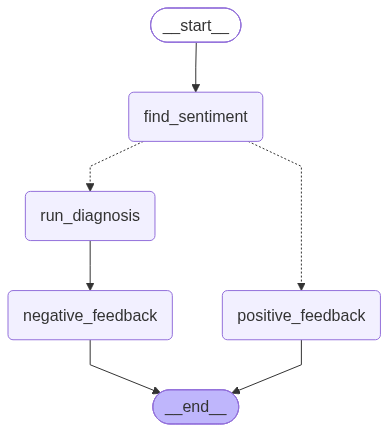

In [14]:
graph = StateGraph(FeedbackState)

graph.add_node("find_sentiment", find_sentiment)
graph.add_node("run_diagnosis", run_diagnosis)
graph.add_node("negative_feedback", negative_feedback)
graph.add_node("positive_feedback", positive_feedback)

graph.add_edge(START, "find_sentiment")
graph.add_conditional_edges("find_sentiment", sentimet_router)
graph.add_edge("run_diagnosis", "negative_feedback")
graph.add_edge("negative_feedback", END)
graph.add_edge("positive_feedback", END)

workflow = graph.compile()
workflow

In [17]:
# initial_state = {'feedback' : "My parcel delivered used cloths now what should i supposed to do with thiss hell i have to goto a function "}
initial_state = {'feedback' : "Yes the quality of cloths are too good"}
final_stage = workflow.invoke(initial_state)
print(final_stage)

{'feedback': 'Yes the quality of cloths are too good', 'sentiment': 'positive', 'positive_response': 'Thank you so much for your wonderful feedback! We are thrilled to hear that you are happy with the quality of our clothing. We look forward to serving you again soon!'}
